# Q1-Q2: Recorded Crashes Across COVID-Related Periods and the Autumn Clock Change

**Owner:** Nguyen Tien Hung (24127391)  
**Dataset:** Traffic Accidents, Chicago (Kaggle snapshot)  
**Scope:** Non-ML questions Q1 and Q2

Question definitions, preprocessing, results, and limitations follow below. Assistance with this review draft is documented in `LLM_USAGE.md`.

In [1]:
from itertools import combinations
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import (
    confint_proportions_2indep,
    proportion_confint,
    proportions_ztest,
)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_raw

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "traffic_accidents.csv"
PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "traffic_accidents_clean.csv"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## Load the shared cleaned data

Run `01_collection_exploration.ipynb` first to prepare the raw and processed files. The main analysis reads the shared processed CSV. Q1 also reads the raw file for the sensitivity check that keeps exact duplicates.

In [2]:
if not PROCESSED_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Processed data not found at {PROCESSED_DATA_PATH}. "
        "Run notebooks/01_collection_exploration.ipynb first."
    )

clean_df = pd.read_csv(PROCESSED_DATA_PATH, parse_dates=["crash_date"])

print(f"Processed data: {PROCESSED_DATA_PATH.relative_to(PROJECT_ROOT)}")
print(f"Rows: {len(clean_df):,}")
print(f"Columns: {clean_df.shape[1]}")
display(clean_df[["crash_date", "crash_year", "crash_hour", "lighting_condition", "has_injury"]].head())

Processed data: data/processed/traffic_accidents_clean.csv
Rows: 209,275
Columns: 29


,crash_date,crash_year,crash_hour,lighting_condition,has_injury
0,2023-07-29 13:00:00,2023,13,DAYLIGHT,False
1,2023-08-13 00:11:00,2023,0,"DARKNESS, LIGHTED ROAD",False
2,2021-12-09 10:30:00,2021,10,DAYLIGHT,False
3,2023-08-09 19:55:00,2023,19,DAYLIGHT,True
4,2023-08-19 14:55:00,2023,14,DAYLIGHT,False


# Q1. Recorded crash trends across COVID-related periods

**Question.** How did monthly recorded crash volume and the share of crashes with at least one reported injury differ across 2018-2019, 2020-2021, and 2022-2024? Do the main comparisons hold under alternative coverage and duplicate rules?

**Motivation.** A traffic-safety planner could use the monthly trend to identify periods that warrant investigation and decide when to seek traffic-volume and reporting data. The labels pre-COVID, COVID and post-COVID describe the calendar groups used in this analysis.

**Depth criteria.** D2 (monthly aggregation, rolling means and same-month comparisons), D5 (95% Wilson intervals and exploratory proportion tests), and D6 (alternative coverage and cleaning rules).

## Q1 preprocessing and method

We keep the processed records for 2018-2024, the full calendar years in the comparison window. The official Chicago source reached citywide coverage during September 2017, and the Kaggle snapshot ends partway through January 2025. The [Chicago Data Portal](https://data.cityofchicago.org/Transportation/Traffic-Crashes-Crashes/85ca-t3if/about_data) documents coverage of the source. The selection process for the Kaggle snapshot is undocumented.

A crash has a reported injury when `injuries_total > 0`. We aggregate to calendar months, smooth both series with a trailing three-month rolling mean, and compare each month's count with the same month a year earlier to partially account for seasonality. The periods contain 24, 24, and 36 months, so volume is compared using **mean crashes per month**. The pooled injury share is injured-crash records divided by all crash records in the period.

Wilson intervals summarize binomial uncertainty. We use two-sided proportion z-tests for the three pairwise contrasts, with Holm adjustment. Those tests treat the crash records as independent. Calendar clustering, reporting practices and how the snapshot was selected can make the nominal uncertainty too small.

In [3]:
def report_filter(name, before, after):
    print(f"{name}")
    print(f"  Rows before: {before:,}")
    print(f"  Rows after:  {after:,}")
    print(f"  Rows removed: {before - after:,}")


q1_before = len(clean_df)
q1_df = clean_df.loc[clean_df["crash_year"].between(2018, 2024)].copy()
report_filter("Q1 complete-year filter (2018-2024)", q1_before, len(q1_df))

period_order = ["Pre-COVID", "COVID", "Post-COVID"]
q1_df["covid_period"] = pd.cut(
    q1_df["crash_year"],
    bins=[2017, 2019, 2021, 2024],
    labels=period_order,
    ordered=True,
)
q1_df["year_month"] = q1_df["crash_date"].dt.to_period("M").dt.to_timestamp()

display(q1_df[["crash_date", "year_month", "covid_period", "has_injury"]].head())

Q1 complete-year filter (2018-2024)
  Rows before: 209,275
  Rows after:  181,051
  Rows removed: 28,224


,crash_date,year_month,covid_period,has_injury
0,2023-07-29 13:00:00,2023-07-01,Post-COVID,False
1,2023-08-13 00:11:00,2023-08-01,Post-COVID,False
2,2021-12-09 10:30:00,2021-12-01,COVID,False
3,2023-08-09 19:55:00,2023-08-01,Post-COVID,True
4,2023-08-19 14:55:00,2023-08-01,Post-COVID,False


In [4]:
monthly_q1 = (
    q1_df.groupby("year_month", as_index=False)
    .agg(
        crashes=("has_injury", "size"),
        injury_crashes=("has_injury", "sum"),
    )
)

monthly_q1["injury_rate"] = monthly_q1["injury_crashes"] / monthly_q1["crashes"]
monthly_q1["crashes_rolling_3m"] = monthly_q1["crashes"].rolling(3, min_periods=1).mean()
monthly_q1["injury_rate_rolling_3m"] = monthly_q1["injury_rate"].rolling(3, min_periods=1).mean()
monthly_q1["crashes_yoy_pct"] = monthly_q1["crashes"].pct_change(12) * 100

expected_months = pd.date_range("2018-01-01", "2024-12-01", freq="MS")
assert pd.DatetimeIndex(monthly_q1["year_month"]).equals(expected_months)
assert monthly_q1["crashes"].sum() == len(q1_df)
print(f"Monthly aggregation: {len(q1_df):,} records across {len(monthly_q1)} months.")
display(
    monthly_q1.nsmallest(5, "crashes_yoy_pct")[
        ["year_month", "crashes", "crashes_yoy_pct"]
    ].round({"crashes_yoy_pct": 2})
)

Monthly aggregation: 181,051 records across 84 months.


,year_month,crashes,crashes_yoy_pct
27,2020-04-01,1092,-50.88
28,2020-05-01,1597,-36.15
26,2020-03-01,1617,-26.63
37,2021-02-01,1660,-24.95
34,2020-11-01,1785,-24.62


In [5]:
period_q1 = (
    q1_df.groupby("covid_period", observed=False, as_index=False)
    .agg(
        crashes=("has_injury", "size"),
        injury_crashes=("has_injury", "sum"),
        months=("year_month", "nunique"),
    )
)
period_q1["mean_crashes_per_month"] = period_q1["crashes"] / period_q1["months"]
pre_covid_monthly_mean = period_q1.loc[0, "mean_crashes_per_month"]
period_q1["volume_change_from_pre_pct"] = (
    period_q1["mean_crashes_per_month"] / pre_covid_monthly_mean - 1
) * 100
period_q1["injury_rate"] = period_q1["injury_crashes"] / period_q1["crashes"]

ci_low, ci_high = proportion_confint(
    count=period_q1["injury_crashes"].to_numpy(),
    nobs=period_q1["crashes"].to_numpy(),
    alpha=0.05,
    method="wilson",
)
period_q1["ci_low"] = ci_low
period_q1["ci_high"] = ci_high
period_q1["injury_rate_pct"] = period_q1["injury_rate"] * 100

display(
    period_q1.assign(ci_low_pct=ci_low * 100, ci_high_pct=ci_high * 100)[
        [
            "covid_period", "months", "crashes", "mean_crashes_per_month",
            "volume_change_from_pre_pct", "injury_crashes", "injury_rate_pct",
            "ci_low_pct", "ci_high_pct",
        ]
    ].round(2)
)

,covid_period,months,crashes,mean_crashes_per_month,volume_change_from_pre_pct,injury_crashes,injury_rate_pct,ci_low_pct,ci_high_pct
0,Pre-COVID,24,55387,2307.79,0.00,14126,25.50,25.14,25.87
1,COVID,24,48466,2019.42,-12.50,13168,27.17,26.78,27.57
2,Post-COVID,36,77198,2144.39,-7.08,21759,28.19,27.87,28.50


## Q1 visual evidence

The first two figures show monthly counts and monthly injury percentages with trailing three-month means. The third shows percentage changes relative to the same month in the previous year. The period comparison figure adds 95% Wilson intervals for the pooled injury percentages.

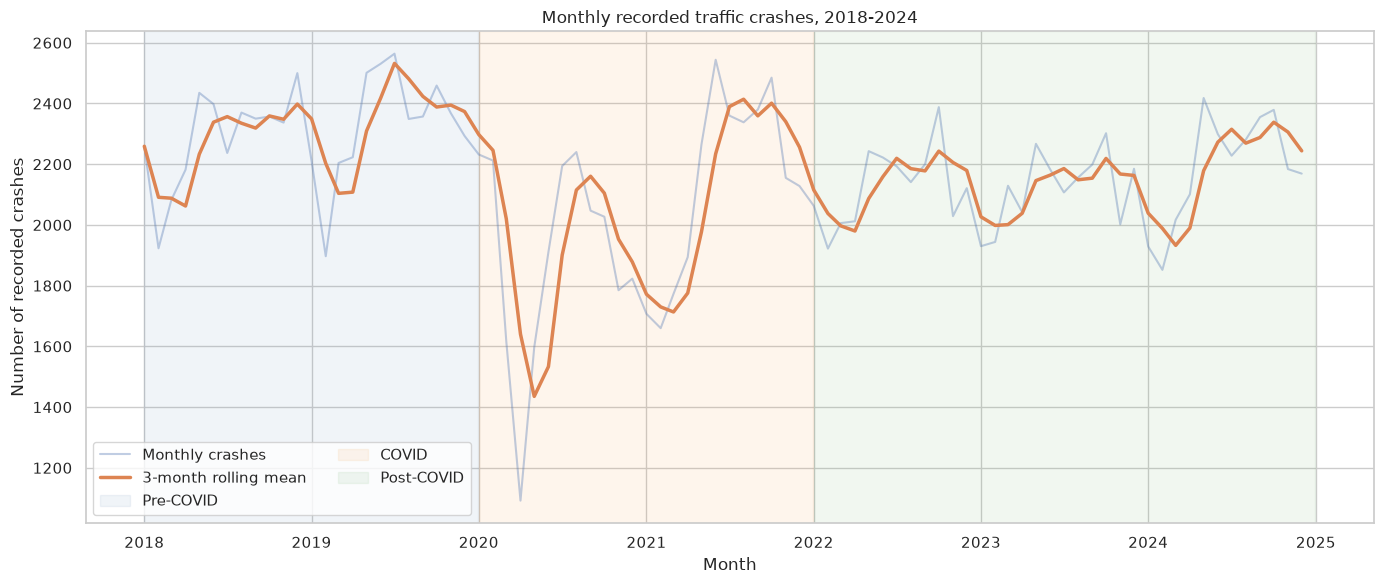

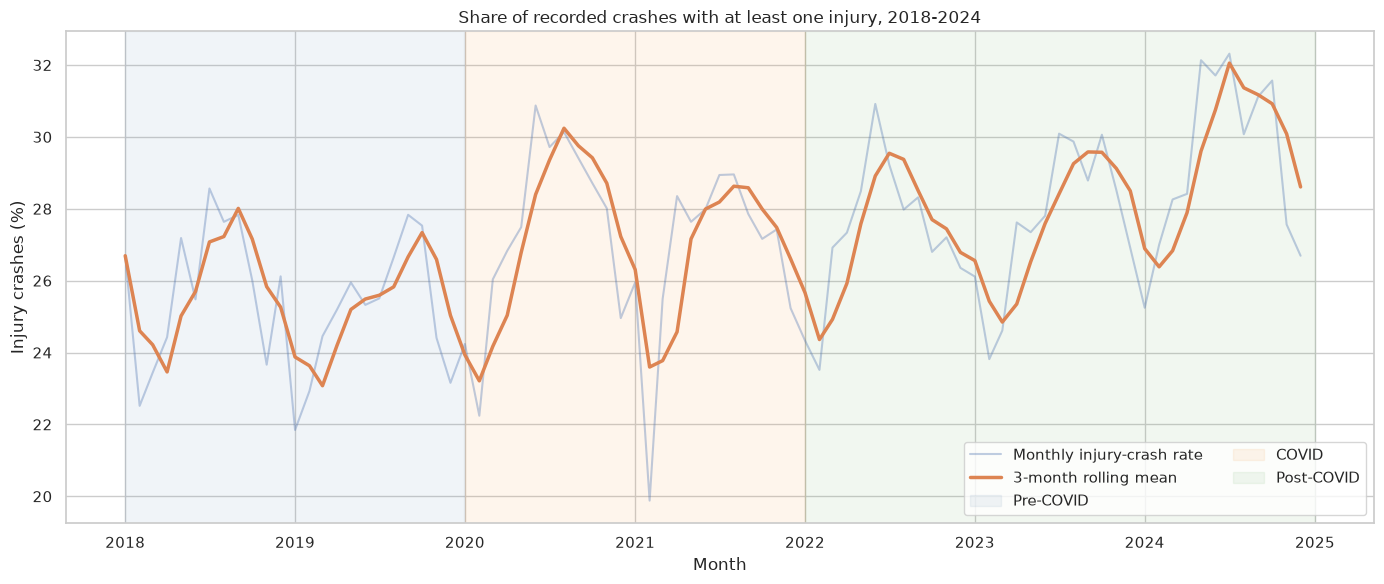

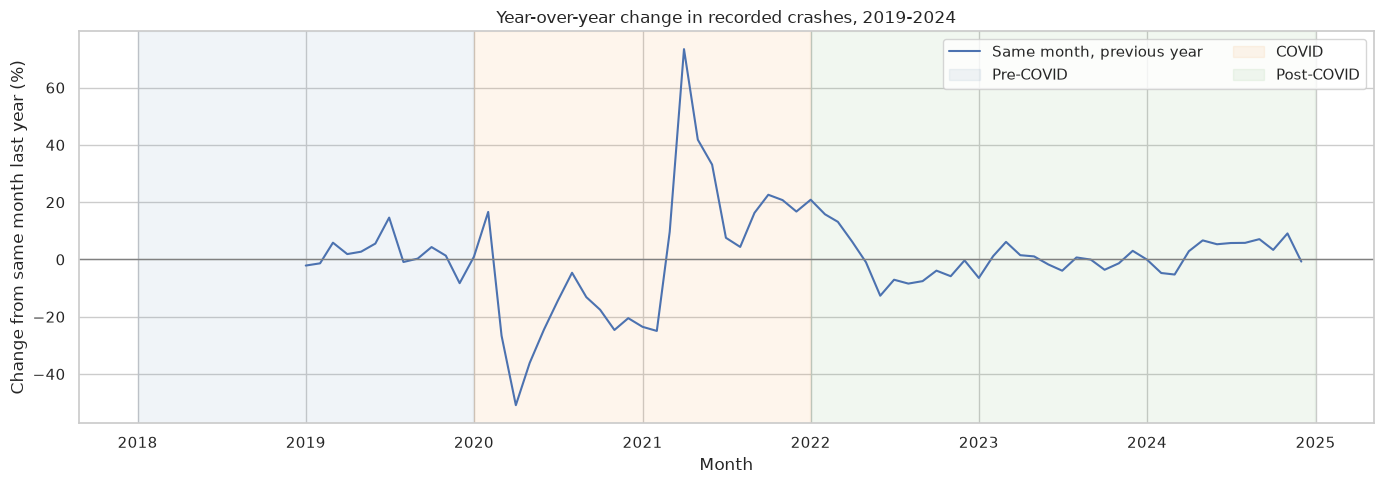

In [6]:
period_spans = [
    (pd.Timestamp("2018-01-01"), pd.Timestamp("2019-12-31"), "#4C78A8", "Pre-COVID"),
    (pd.Timestamp("2020-01-01"), pd.Timestamp("2021-12-31"), "#F58518", "COVID"),
    (pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"), "#54A24B", "Post-COVID"),
]

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(monthly_q1["year_month"], monthly_q1["crashes"], alpha=0.35, label="Monthly crashes")
ax.plot(monthly_q1["year_month"], monthly_q1["crashes_rolling_3m"], linewidth=2.5, label="3-month rolling mean")
for start, end, color, label in period_spans:
    ax.axvspan(start, end, color=color, alpha=0.08, label=label)
ax.set(title="Monthly recorded traffic crashes, 2018-2024", xlabel="Month", ylabel="Number of recorded crashes")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(monthly_q1["year_month"], monthly_q1["injury_rate"] * 100, alpha=0.35, label="Monthly injury-crash rate")
ax.plot(monthly_q1["year_month"], monthly_q1["injury_rate_rolling_3m"] * 100, linewidth=2.5, label="3-month rolling mean")
for start, end, color, label in period_spans:
    ax.axvspan(start, end, color=color, alpha=0.08, label=label)
ax.set(title="Share of recorded crashes with at least one injury, 2018-2024", xlabel="Month", ylabel="Injury crashes (%)")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly_q1["year_month"], monthly_q1["crashes_yoy_pct"], label="Same month, previous year")
ax.axhline(0, color="gray", linewidth=1)
for start, end, color, label in period_spans:
    ax.axvspan(start, end, color=color, alpha=0.08, label=label)
ax.set(
    title="Year-over-year change in recorded crashes, 2019-2024",
    xlabel="Month", ylabel="Change from same month last year (%)",
)
ax.legend(ncol=2)
fig.tight_layout()
plt.show()

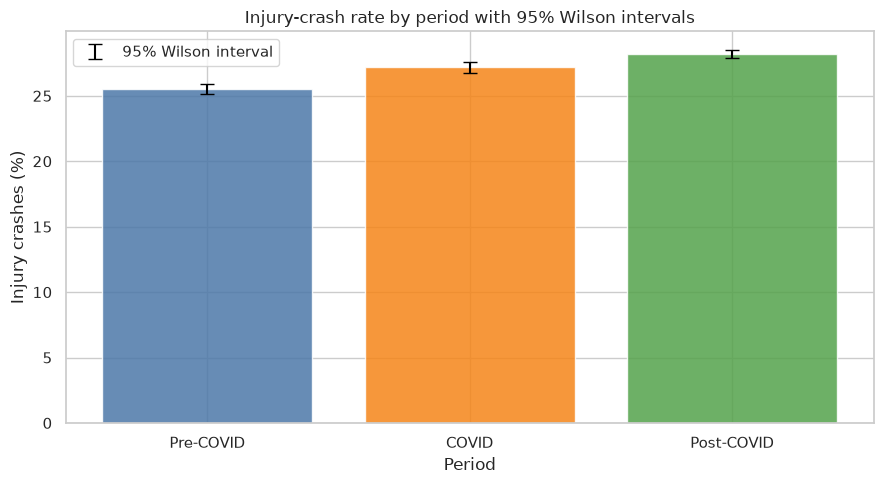

,comparison,difference_percentage_points,z_statistic,p_value,p_value_holm
0,COVID minus Pre-COVID,1.665382,6.082951,1.179905e-09,2.359811e-09
1,Post-COVID minus Pre-COVID,2.681784,10.839473,2.237559e-27,6.712676e-27
2,Post-COVID minus COVID,1.016401,3.914888,9.044608e-05,9.044608e-05


In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(period_q1))
rates = period_q1["injury_rate_pct"].to_numpy()
errors = np.vstack([
    rates - period_q1["ci_low"].to_numpy() * 100,
    period_q1["ci_high"].to_numpy() * 100 - rates,
])
ax.bar(x, rates, color=["#4C78A8", "#F58518", "#54A24B"], alpha=0.85)
ax.errorbar(x, rates, yerr=errors, fmt="none", color="black", capsize=5, label="95% Wilson interval")
ax.set_xticks(x, period_q1["covid_period"].astype(str))
ax.set(title="Injury-crash rate by period with 95% Wilson intervals", xlabel="Period", ylabel="Injury crashes (%)")
ax.legend()
plt.tight_layout()
plt.show()

period_index = period_q1.set_index(period_q1["covid_period"].astype(str))
test_records = []
for left, right in combinations(period_order, 2):
    counts = [period_index.loc[left, "injury_crashes"], period_index.loc[right, "injury_crashes"]]
    totals = [period_index.loc[left, "crashes"], period_index.loc[right, "crashes"]]
    z_stat, p_value = proportions_ztest(count=counts[::-1], nobs=totals[::-1])
    effect_pp = (counts[1] / totals[1] - counts[0] / totals[0]) * 100
    test_records.append({
        "comparison": f"{right} minus {left}",
        "difference_percentage_points": effect_pp,
        "z_statistic": z_stat,
        "p_value": p_value,
    })

q1_tests = pd.DataFrame(test_records)
q1_tests["p_value_holm"] = multipletests(q1_tests["p_value"], method="holm")[1]
display(q1_tests)

## Q1 robustness checks

1. **Retain exact duplicate rows.** Recreate the same period labels and injury definition from the raw CSV. Compare counts, monthly means and injury percentages with the processed-data analysis.
2. **Start in September 2017.** Add September-December 2017 to the pre-COVID group and recompute its monthly mean and injury share. September 1 is the operational cutoff for this sensitivity check. The source describes the transition by month, and the selection of the Kaggle records remains uncertain.
3. **Split 2020 and 2021.** Compare their annual counts and injury percentages to see whether the pooled COVID-period estimate hides differences between the two years.

In [8]:
raw_q1 = load_raw(RAW_DATA_PATH)
raw_q1["crash_date"] = pd.to_datetime(
    raw_q1["crash_date"], format="%m/%d/%Y %I:%M:%S %p", errors="raise"
)
raw_q1["crash_year"] = raw_q1["crash_date"].dt.year
raw_q1["has_injury"] = raw_q1["injuries_total"] > 0
raw_rows_before = len(raw_q1)
raw_q1 = raw_q1.loc[raw_q1["crash_year"].between(2018, 2024)].copy()
report_filter("Q1 raw-data sensitivity (2018-2024)", raw_rows_before, len(raw_q1))
raw_q1["covid_period"] = pd.cut(
    raw_q1["crash_year"], bins=[2017, 2019, 2021, 2024], labels=period_order, ordered=True
)

raw_period = raw_q1.groupby("covid_period", observed=False).agg(
    raw_crashes=("has_injury", "size"), raw_injury_rate=("has_injury", "mean")
)
duplicate_sensitivity = period_q1.set_index("covid_period")[["crashes", "months", "injury_rate"]].join(raw_period)
duplicate_sensitivity["extra_records"] = duplicate_sensitivity["raw_crashes"] - duplicate_sensitivity["crashes"]
duplicate_sensitivity["extra_records_per_month"] = duplicate_sensitivity["extra_records"] / duplicate_sensitivity["months"]
duplicate_sensitivity["injury_share_change_pp"] = (
    duplicate_sensitivity["raw_injury_rate"] - duplicate_sensitivity["injury_rate"]
) * 100
display(
    duplicate_sensitivity[
        ["crashes", "raw_crashes", "extra_records", "extra_records_per_month", "injury_share_change_pp"]
    ].round(4)
)

early_window = clean_df.loc[clean_df["crash_date"].between("2017-09-01", "2020-01-01", inclusive="left")]
report_filter("Q1 extended baseline (September 2017-December 2019)", len(clean_df), len(early_window))
print(f"Records added to the original baseline: {len(early_window) - period_q1.loc[0, 'crashes']:,}")
early_months = early_window["crash_date"].dt.to_period("M").nunique()
early_baseline = pd.DataFrame(
    {
        "months": [period_q1.loc[0, "months"], early_months],
        "crashes": [period_q1.loc[0, "crashes"], len(early_window)],
        "mean_crashes_per_month": [pre_covid_monthly_mean, len(early_window) / early_months],
        "injury_rate_pct": [period_q1.loc[0, "injury_rate_pct"], early_window["has_injury"].mean() * 100],
    },
    index=["Original 2018-2019", "Extended from September 2017"],
)
display(early_baseline.round(2))

covid_years = q1_df.loc[q1_df["crash_year"].between(2020, 2021)]
report_filter("Q1 split COVID period into individual years", len(q1_df), len(covid_years))
annual_covid = covid_years.groupby("crash_year").agg(
    crashes=("has_injury", "size"), injury_rate=("has_injury", "mean")
)
display(annual_covid.assign(injury_rate_pct=annual_covid["injury_rate"] * 100).drop(columns="injury_rate").round(2))

Q1 raw-data sensitivity (2018-2024)
  Rows before: 209,306
  Rows after:  181,081
  Rows removed: 28,225


,crashes,raw_crashes,extra_records,extra_records_per_month,injury_share_change_pp
covid_period,,,,,
Pre-COVID,55387,55397,10,0.4167,-0.0028
COVID,48466,48473,7,0.2917,0.0085
Post-COVID,77198,77211,13,0.3611,-0.0022


Q1 extended baseline (September 2017-December 2019)
  Rows before: 209,275
  Rows after:  64,204
  Rows removed: 145,071
Records added to the original baseline: 8,817


,months,crashes,mean_crashes_per_month,injury_rate_pct
Original 2018-2019,24,55387,2307.79,25.50
Extended from September 2017,28,64204,2293.00,25.75


Q1 split COVID period into individual years
  Rows before: 181,051
  Rows after:  48,466
  Rows removed: 132,585


,crashes,injury_rate_pct
crash_year,,
2020,22777,27.40
2021,25689,26.96


## Q1 results and interpretation

- **Monthly volume.** The mean count fell from **2,307.8 per month** in 2018-2019 to **2,019.4** in 2020-2021 (**−12.5%**). It recovered to **2,144.4** in 2022-2024, still **7.1% below** the pre-COVID mean. April 2020 had the lowest count of the seven-year window (**1,092**), **50.9% fewer** than April 2019.
- **Share with injury.** The recorded share rose from **25.50%** (95% Wilson interval **25.14–25.87%**) to **27.17%** (**26.78–27.57%**) and then **28.19%** (**27.87–28.50%**). The last period was **2.68 percentage points** above the baseline. All three nominal contrasts have Holm-adjusted `p < 0.001`. The temporal dependence of crash records and the snapshot's unknown selection limit inference from these tests.
- **Robustness.** Keeping the exact duplicate rows changes each injury share by less than **0.01 percentage points** and each monthly mean by less than one record. Adding **8,817** records from September-December 2017 gives a baseline of **2,293.0 records per month** and **25.75% with injury**. The main directions are unchanged. Examined separately, **2020 had fewer records than 2021** (22,777 vs. 25,689), while the recorded injury share was slightly higher in 2020 (27.40% vs. 26.96%).

**Practical meaning and limitations.** Fewer recorded crashes per month and a higher share involving injury can occur together. Traffic counts, trip mix, reporting behavior and coverage would be needed to explain the changes or estimate the risk per trip. The three periods describe observed changes and cannot isolate a causal COVID effect.

# Q2. Autumn clock change and crashes recorded in darkness

**Question.** Across 2018-2024, did the number of crashes recorded in darkness during 16:00-18:59 and the share of those crashes with reported injury increase in the 14 days after Chicago returned to standard time, compared with the 14 days before?

**Motivation.** Traffic-safety planners could use the pattern to decide whether to study the weeks around the clock change, including whether lighting or driver communication warrants closer examination.

**External data.** The calendar table is derived from the [NIST daylight saving time rule](https://www.nist.gov/pml/time-and-frequency-division/popular-links/daylight-saving-time-dst). In the years studied, the clocks returned to standard time at 02:00 local time on the first Sunday in November. The resulting seven transition dates are joined to crash records by year.

**Depth criteria.** D1 (documented calendar join), D2 (paired time windows), D3 (relative day and dark rush-hour indicators), and D5 (paired count test, confidence intervals and a proportion test).

In [9]:
def first_sunday_of_november(year):
    candidates = pd.date_range(f"{year}-11-01", periods=7, freq="D")
    return candidates[candidates.day_of_week == 6][0]


dst_table = pd.DataFrame({"year": range(2018, 2025)})
dst_table["dst_end_date"] = dst_table["year"].map(first_sunday_of_november)
dst_table["source"] = "NIST DST rule: first Sunday in November"
dst_table["source_url"] = "https://www.nist.gov/pml/time-and-frequency-division/popular-links/daylight-saving-time-dst"
display(dst_table)

,year,dst_end_date,source,source_url
0,2018,2018-11-04,NIST DST rule: first Sunday in November,https://www.nist.gov/pml/time-and-frequency-di...
1,2019,2019-11-03,NIST DST rule: first Sunday in November,https://www.nist.gov/pml/time-and-frequency-di...
2,2020,2020-11-01,NIST DST rule: first Sunday in November,https://www.nist.gov/pml/time-and-frequency-di...
3,2021,2021-11-07,NIST DST rule: first Sunday in November,https://www.nist.gov/pml/time-and-frequency-di...
4,2022,2022-11-06,NIST DST rule: first Sunday in November,https://www.nist.gov/pml/time-and-frequency-di...
5,2023,2023-11-05,NIST DST rule: first Sunday in November,https://www.nist.gov/pml/time-and-frequency-di...
6,2024,2024-11-03,NIST DST rule: first Sunday in November,https://www.nist.gov/pml/time-and-frequency-di...


## Q2 preprocessing and method

- **Before:** relative days −14 to −1. **After:** relative days 0 to 13. Day 0 is the transition Sunday. At the selected afternoon hours on day 0, the clock change has already taken place.
- **Rush hour:** 16:00-18:59 in the recorded local time, on every day of the week. The two windows each include two of every weekday.
- **Darkness:** the reported lighting labels `DARKNESS` and `DARKNESS, LIGHTED ROAD`. `DAWN`, `DUSK` and `UNKNOWN` are outside this definition. The all-rush-hour denominators include every lighting label, and `UNKNOWN` is reported separately.
- **Injury percentage:** records with any reported injury divided by the dark rush-hour crashes in each window.

Count pairs are matched by year. An exact two-sided Wilcoxon signed-rank test evaluates the paired count differences under the null of a symmetric distribution of differences centered at zero. We also report the median paired difference. Pooled injury shares use 95% Wilson intervals, and the after-minus-before contrast uses a Newcombe 95% interval and a two-sided proportion z-test. The injury test and intervals use a working assumption of independent crash records. They are exploratory because records may cluster in time or by conditions. Two alternative hour ranges test how sensitive the results are to the rush-hour definition.

In [10]:
q2_before = len(clean_df)
q2_base = clean_df.loc[clean_df["crash_year"].between(2018, 2024)].copy()
report_filter("Q2 year filter (2018-2024)", q2_before, len(q2_base))

merge_before = len(q2_base)
q2_base = q2_base.merge(
    dst_table, left_on="crash_year", right_on="year", how="left",
    validate="many_to_one", indicator=True,
)
print(f"Rows before merge: {merge_before:,}")
print(f"Rows after merge:  {len(q2_base):,}")
unmatched = (q2_base["_merge"] != "both").sum()
print(f"Unmatched rows: {unmatched:,}")
assert len(q2_base) == merge_before and unmatched == 0

q2_base["crash_day"] = q2_base["crash_date"].dt.normalize()
q2_base["days_from_dst_end"] = (q2_base["crash_day"] - q2_base["dst_end_date"]).dt.days
window_before = len(q2_base)
q2_window = q2_base.loc[q2_base["days_from_dst_end"].between(-14, 13)].copy()
report_filter("Q2 symmetric 28-day window", window_before, len(q2_window))

q2_window["dst_period"] = np.where(q2_window["days_from_dst_end"] < 0, "Before", "After")
q2_window["dst_period"] = pd.Categorical(q2_window["dst_period"], categories=["Before", "After"], ordered=True)
q2_window["is_rush_hour"] = q2_window["crash_hour"].between(16, 18)
dark_labels = {"DARKNESS", "DARKNESS, LIGHTED ROAD"}
q2_window["is_dark"] = q2_window["lighting_condition"].isin(dark_labels)

q2_rush = q2_window.loc[q2_window["is_rush_hour"]].copy()
report_filter("Q2 rush-hour subset (16:00-18:59)", len(q2_window), len(q2_rush))
q2_dark = q2_rush.loc[q2_rush["is_dark"]].copy()
report_filter("Q2 dark lighting subset", len(q2_rush), len(q2_dark))

Q2 year filter (2018-2024)
  Rows before: 209,275
  Rows after:  181,051
  Rows removed: 28,224
Rows before merge: 181,051
Rows after merge:  181,051
Unmatched rows: 0
Q2 symmetric 28-day window
  Rows before: 181,051
  Rows after:  14,643
  Rows removed: 166,408
Q2 rush-hour subset (16:00-18:59)
  Rows before: 14,643
  Rows after:  3,148
  Rows removed: 11,495
Q2 dark lighting subset
  Rows before: 3,148
  Rows after:  1,487
  Rows removed: 1,661


In [11]:
q2_yearly = q2_dark.groupby(["crash_year", "dst_period"], observed=False, as_index=False).agg(
    crashes=("has_injury", "size"), injury_crashes=("has_injury", "sum")
)
q2_yearly["injury_rate_pct"] = q2_yearly["injury_crashes"] / q2_yearly["crashes"] * 100

q2_overall = q2_dark.groupby("dst_period", observed=False, as_index=False).agg(
    crashes=("has_injury", "size"), injury_crashes=("has_injury", "sum")
)
q2_overall["injury_rate"] = q2_overall["injury_crashes"] / q2_overall["crashes"]
q2_low, q2_high = proportion_confint(q2_overall["injury_crashes"], q2_overall["crashes"], method="wilson")
q2_overall["ci_low"] = q2_low
q2_overall["ci_high"] = q2_high
q2_overall["injury_rate_pct"] = q2_overall["injury_rate"] * 100
q2_rush["unknown_lighting"] = q2_rush["lighting_condition"].eq("UNKNOWN")
q2_lighting_context = q2_rush.groupby("dst_period", observed=False).agg(
    all_rush_crashes=("is_dark", "size"),
    dark_crashes=("is_dark", "sum"),
    unknown_lighting=("unknown_lighting", "sum"),
)
q2_lighting_context["dark_pct_of_all_rush"] = (
    100 * q2_lighting_context["dark_crashes"] / q2_lighting_context["all_rush_crashes"]
)
assert q2_lighting_context["dark_crashes"].sum() == len(q2_dark)

display(q2_yearly.round(2))
display(q2_lighting_context.round(2))
display(
    q2_overall.assign(ci_low_pct=q2_low * 100, ci_high_pct=q2_high * 100)[
        ["dst_period", "crashes", "injury_crashes", "injury_rate_pct", "ci_low_pct", "ci_high_pct"]
    ].round(2)
)

,crash_year,dst_period,crashes,injury_crashes,injury_rate_pct
0,2018,Before,74,25,33.78
1,2018,After,185,42,22.70
2,2019,Before,74,25,33.78
3,2019,After,154,32,20.78
4,2020,Before,47,16,34.04
5,2020,After,115,31,26.96
6,2021,Before,80,24,30.00
7,2021,After,157,42,26.75
8,2022,Before,60,13,21.67
9,2022,After,124,30,24.19


,all_rush_crashes,dark_crashes,unknown_lighting,dark_pct_of_all_rush
dst_period,,,,
Before,1517,451,61,29.73
After,1631,1036,72,63.52


,dst_period,crashes,injury_crashes,injury_rate_pct,ci_low_pct,ci_high_pct
0,Before,451,126,27.94,24.0,32.25
1,After,1036,267,25.77,23.2,28.52


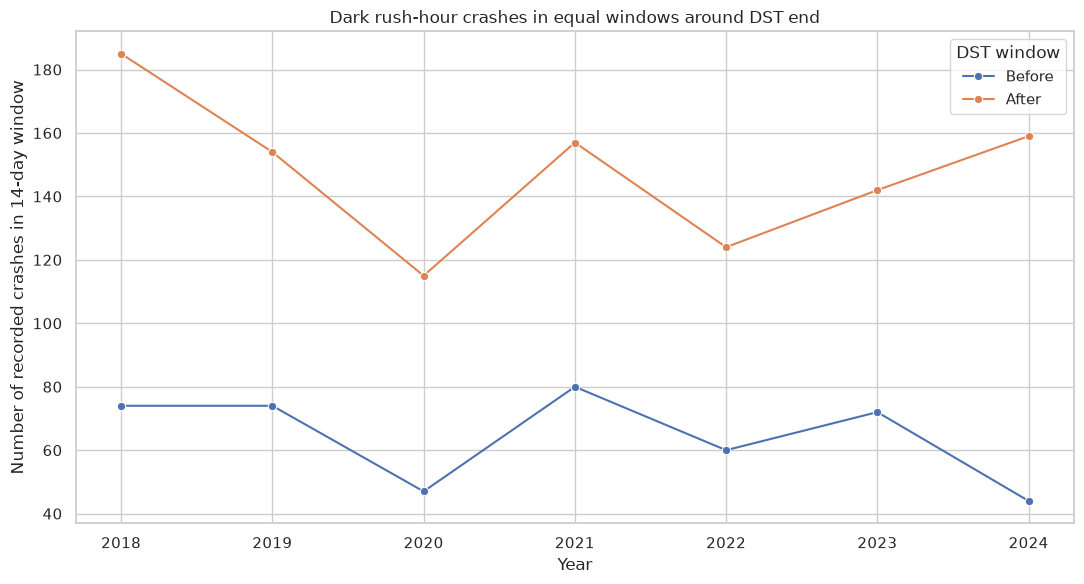

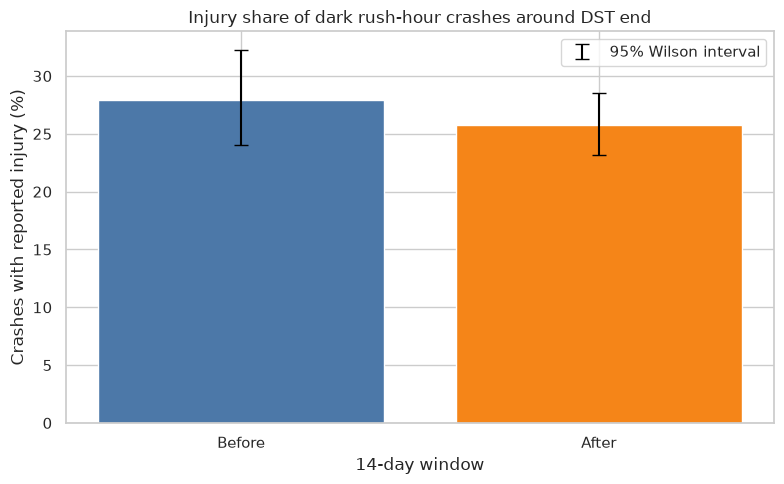

In [12]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.lineplot(data=q2_yearly, x="crash_year", y="crashes", hue="dst_period", marker="o", ax=ax)
ax.get_legend().set_title("DST window")
ax.set(title="Dark rush-hour crashes in equal windows around DST end", xlabel="Year", ylabel="Number of recorded crashes in 14-day window")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(q2_overall))
rates = q2_overall["injury_rate_pct"].to_numpy()
errors = np.vstack([rates - q2_overall["ci_low"].to_numpy() * 100, q2_overall["ci_high"].to_numpy() * 100 - rates])
ax.bar(x, rates, color=["#4C78A8", "#F58518"])
ax.errorbar(x, rates, yerr=errors, fmt="none", color="black", capsize=5, label="95% Wilson interval")
ax.set_xticks(x, q2_overall["dst_period"].astype(str))
ax.set(
    title="Injury share of dark rush-hour crashes around DST end",
    xlabel="14-day window", ylabel="Crashes with reported injury (%)",
)
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
count_pairs = q2_yearly.pivot(index="crash_year", columns="dst_period", values="crashes")
assert count_pairs.index.tolist() == list(range(2018, 2025))
assert count_pairs[["Before", "After"]].notna().all().all()
count_differences = count_pairs["After"] - count_pairs["Before"]
w_stat, w_p = wilcoxon(count_differences, alternative="two-sided", method="exact")

q2_index = q2_overall.set_index("dst_period")
q2_counts = [q2_index.loc["After", "injury_crashes"], q2_index.loc["Before", "injury_crashes"]]
q2_totals = [q2_index.loc["After", "crashes"], q2_index.loc["Before", "crashes"]]
q2_z, q2_p = proportions_ztest(q2_counts, q2_totals)
q2_effect_pp = (q2_counts[0] / q2_totals[0] - q2_counts[1] / q2_totals[1]) * 100
q2_ci_low, q2_ci_high = confint_proportions_2indep(
    q2_counts[0], q2_totals[0], q2_counts[1], q2_totals[1],
    method="newcomb", compare="diff",
)

q2_tests = pd.Series({
    "years_with_more_dark_crashes_after": (count_differences > 0).sum(),
    "median_paired_count_difference": count_differences.median(),
    "pooled_count_change_pct": 100 * (q2_totals[0] / q2_totals[1] - 1),
    "paired_wilcoxon_statistic_for_counts": w_stat,
    "paired_wilcoxon_p_value_for_counts": w_p,
    "injury_share_after_minus_before_pp": q2_effect_pp,
    "injury_share_difference_ci_low_pp": 100 * q2_ci_low,
    "injury_share_difference_ci_high_pp": 100 * q2_ci_high,
    "two_proportion_z_statistic": q2_z,
    "two_proportion_p_value": q2_p,
})
display(q2_tests.to_frame("value").round(4))

,value
years_with_more_dark_crashes_after,7.0000
median_paired_count_difference,77.0000
pooled_count_change_pct,129.7118
paired_wilcoxon_statistic_for_counts,0.0000
paired_wilcoxon_p_value_for_counts,0.0156
injury_share_after_minus_before_pp,-2.1657
injury_share_difference_ci_low_pp,-7.1875
injury_share_difference_ci_high_pp,2.6399
two_proportion_z_statistic,-0.8706
two_proportion_p_value,0.3840


In [14]:
sensitivity_records = []
for label, start_hour, end_hour in [
    ("15:00-17:59", 15, 17),
    ("16:00-18:59", 16, 18),
    ("16:00-19:59", 16, 19),
]:
    subset = q2_window.loc[
        q2_window["crash_hour"].between(start_hour, end_hour) & q2_window["is_dark"]
    ]
    report_filter(f"Q2 sensitivity: dark crashes in {label}", len(q2_window), len(subset))
    summary = subset.groupby("dst_period", observed=False).agg(
        crashes=("has_injury", "size"), injury_crashes=("has_injury", "sum")
    )
    injury_pct = 100 * summary["injury_crashes"] / summary["crashes"]
    sensitivity_records.append({
        "hours": label,
        "before_crashes": summary.loc["Before", "crashes"],
        "after_crashes": summary.loc["After", "crashes"],
        "before_injury_pct": injury_pct.loc["Before"],
        "after_injury_pct": injury_pct.loc["After"],
        "injury_share_after_minus_before_pp": injury_pct.loc["After"] - injury_pct.loc["Before"],
    })

q2_sensitivity = pd.DataFrame(sensitivity_records)
display(q2_sensitivity.round(2))

Q2 sensitivity: dark crashes in 15:00-17:59
  Rows before: 14,643
  Rows after:  745
  Rows removed: 13,898
Q2 sensitivity: dark crashes in 16:00-18:59
  Rows before: 14,643
  Rows after:  1,487
  Rows removed: 13,156
Q2 sensitivity: dark crashes in 16:00-19:59
  Rows before: 14,643
  Rows after:  2,126
  Rows removed: 12,517


,hours,before_crashes,after_crashes,before_injury_pct,after_injury_pct,injury_share_after_minus_before_pp
0,15:00-17:59,128,617,24.22,27.07,2.85
1,16:00-18:59,451,1036,27.94,25.77,-2.17
2,16:00-19:59,784,1342,29.46,27.05,-2.42


## Q2 results and interpretation

- **Recorded crash counts.** Dark rush-hour crashes rose from **451 before** to **1,036 after** (**+585 records, +129.7% pooled**). The after count was higher in **all 7 years**, with a median increase of **77 records** per matched year and a two-sided exact Wilcoxon `p = 0.0156`. The total across **all lighting conditions** changed from **1,517 to 1,631**, while the recorded dark share of those rush-hour crashes rose from **29.73% to 63.52%**. Much of the difference is therefore in the lighting composition of records within the fixed clock-hour window.
- **Injury counts and percentages.** Dark rush-hour crashes with reported injury rose in absolute number (**126 to 267**), while the share with injury was **27.94% before** and **25.77% after**. The after-minus-before difference was **−2.17 percentage points** (95% Newcombe interval **−7.19 to +2.64**, nominal `p = 0.384`). These data do not provide clear statistical evidence of a change in the pooled injury percentage.
- **Sensitivity.** Dark crash counts remained higher after the transition for all three clock-hour definitions. The injury-share difference changed sign when we used 15:00-17:59 (**+2.85 percentage points**), so the direction of the injury-share change is sensitive to the hour definition.

**Practical meaning and limitations.** The clock change shifts daylight relative to the hours used in the analysis. A crash at the same clock hour can be coded dark in one window and daylight in the other. Weather, seasonality, holidays, travel behavior and reporting can also differ between windows. The results describe records in the Kaggle snapshot. Estimating how the clock change affects crash risk would require traffic exposure and a design that addresses those time-related differences.

## Summary for the group

| Question | Main finding | Important qualification |
|---|---|---|
| Q1 | Recorded crashes per month fell in 2020-2021 and partly recovered in 2022-2024. The share with injury increased across the three periods. | The periods describe a pattern in the snapshot. Exposure and reporting data are needed to explain it. |
| Q2 | More crashes were recorded in darkness during the fixed rush-hour window after the autumn clock change in every year studied. | The pooled injury-share difference was uncertain and its direction depended on the hour definition. |

The shared dataset and its preparation are documented in `01_collection_exploration.ipynb`. Q2's supplementary calendar is generated in this notebook from the NIST rule.